In [2]:
# Imports
from backend import * # See backend.py

import torch
torch.set_default_dtype(torch.float64)
import matplotlib.pyplot as plt
import matplotlib as mpl
import numpy as np
from torch import nn
from geomloss import SamplesLoss
from sklearn.datasets import make_swiss_roll
import os
import shutil
from matplotlib.legend_handler import HandlerTuple

device = 'cuda' if torch.cuda.is_available() else 'cpu'
device

'cuda'

# Gradient Flows of the Gaussian Sinkhorn divergence 

In [2]:
# Parameters
sigma_0 = torch.tensor([[.6, .3],
                        [.3, .6]])
sigma_target_non_singular = torch.diag(torch.tensor([1., .2]))
sigma_target_singular = torch.diag(torch.tensor([1., 0.]))
t = torch.linspace(0, 3, 200)
blur = .5
# Compute flows
sigma_t_non_singular = GaussianWGFS(blur, sigma_target_non_singular).integrate(sigma_0, t)
sigma_t_singular = GaussianWGFS(blur, sigma_target_singular).integrate(sigma_0, t)

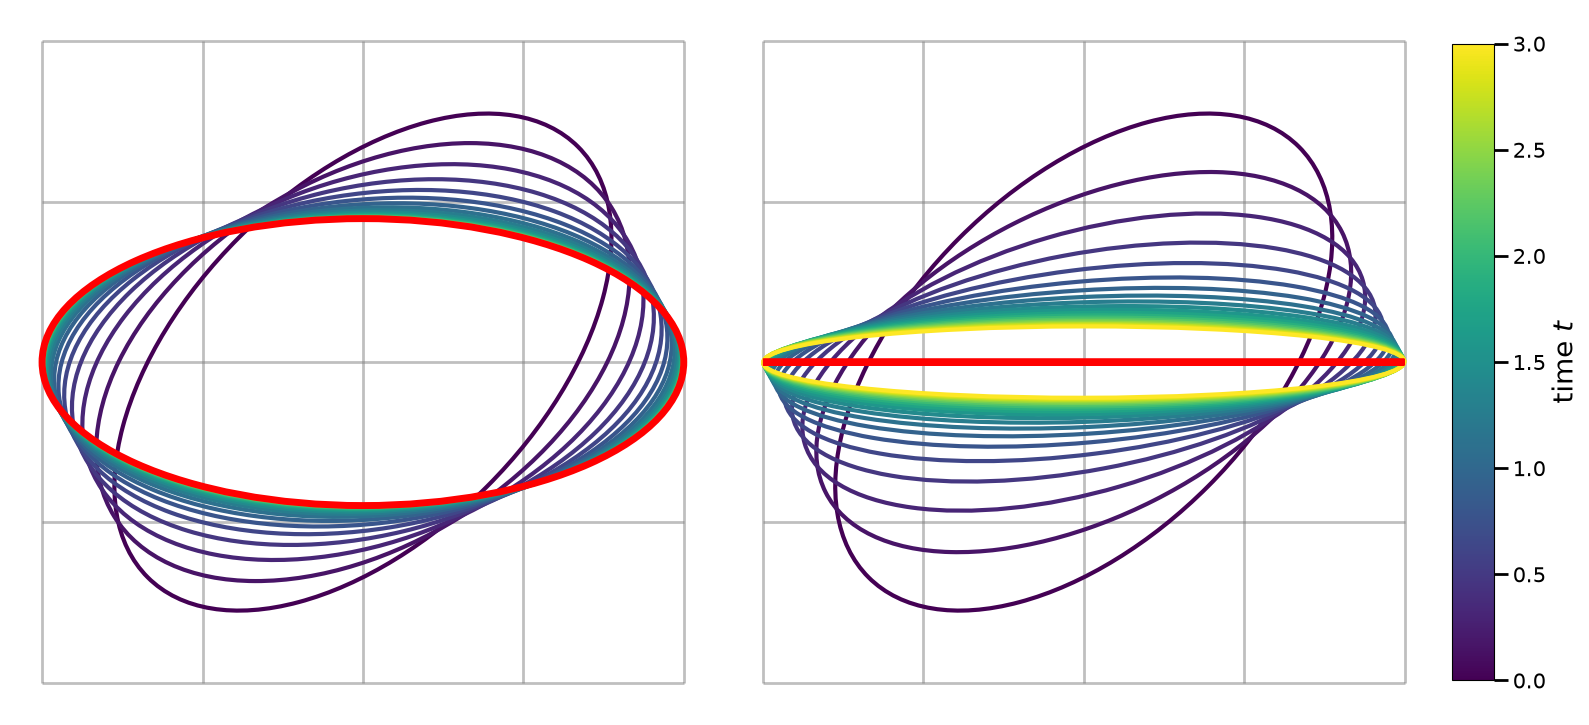

In [3]:
# Figure 1
figsize = (16, 8)
xm, xM = -1, 1
ym, yM = -1, 1

fig, (ax1, ax2, cax) = plt.subplots(1, 3, figsize=figsize, width_ratios=[1, 1, .06])
for ax, sig_t, sig_target in zip([ax1, ax2], [sigma_t_non_singular, sigma_t_singular], [sigma_target_non_singular, sigma_target_singular]):
    ax.set_xlim(xm-.1, xM+.1)
    ax.set_ylim(ym-.1, yM+.1)
    ax.hlines(np.arange(ym, yM+blur, blur), xm , xM, zorder=-1, color='gray', alpha=.5, linewidth=2)
    ax.vlines(np.arange(xm, xM+blur, blur), ym , yM, zorder=-1, color='gray', alpha=.5, linewidth=2)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax = plot_gaussian_flow(ax, sig_t, sig_target, subsample=10, kw=dict(linewidth=3), kw_target=dict(linewidth=5))

fig.colorbar(mpl.cm.ScalarMappable(cmap=plt.get_cmap('viridis'), norm=mpl.colors.Normalize(vmin=0, vmax=t[-1])), cax=cax)
cax.tick_params(axis='both', which="major", labelsize=15, length=10, width=2)
cax.set_ylabel("time $t$", size=20)
fig.tight_layout()
pos = cax.get_position()
cax.set_position([
    pos.x0,
    pos.y0 + 0.075 * pos.height,
    pos.width,
    0.85 * pos.height
])

In [4]:
# Parameters
sigma_0_ortho = torch.tensor([[0., 0.],
                              [0, 1.]])
t = torch.linspace(0, 2, 200)
sigma_target = torch.diag(torch.tensor([1., 0.]))

def rot(theta):
    return torch.tensor([[np.cos(theta), np.sin(theta)], [-np.sin(theta), np.cos(theta)]])
P = rot(0.01)
sigma_0_non_ortho = P @ torch.tensor([[0., 0.],
                                      [0, 1.]]) @ P.T

# Compute flows
sigma_t_ortho = GaussianWGFS(blur, sigma_target).integrate(sigma_0_ortho, t)
sigma_t_non_ortho = GaussianWGFS(blur, sigma_target).integrate(sigma_0_non_ortho, t)

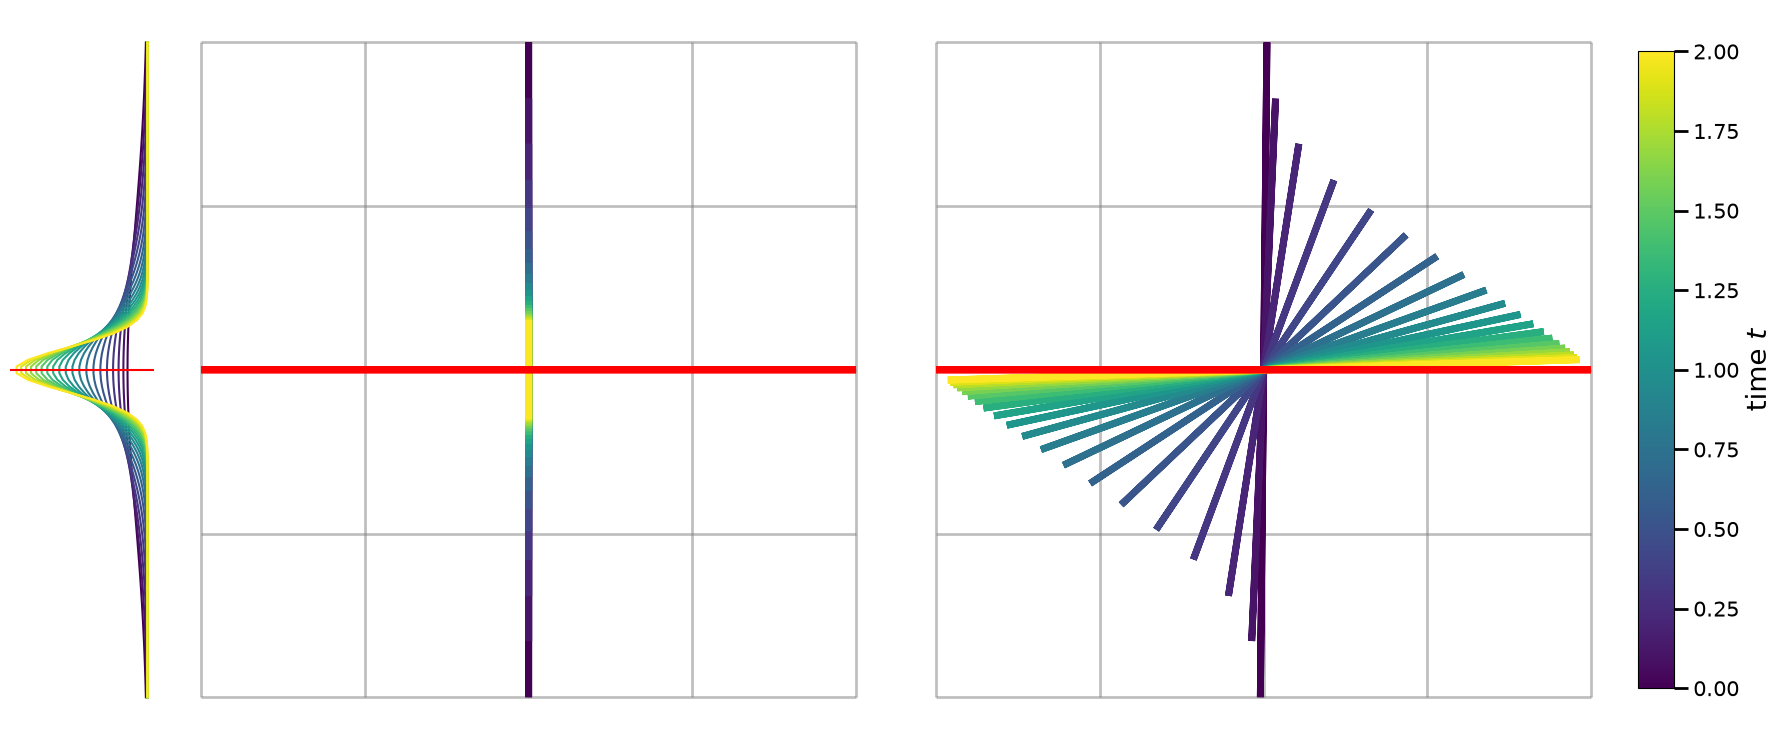

In [5]:
# Figure 2
figsize = (16, 8)
xm, xM = -1, 1
ym, yM = -1, 1

fig = plt.figure(figsize=(18, 8))
spec = fig.add_gridspec(1, 3, width_ratios=[1, 1, .05])
ax1 = fig.add_subplot(spec[0, 0])
ax1.set_aspect("equal")
ax1.set_xlim(xm-.1, xM+.1)
ax1.set_ylim(ym-.1, yM+.1)
ax1_y = ax1.inset_axes(
    [-.22, 0., .2, 1],
    transform=ax1.transAxes,
    sharey=ax1
)
ax2 = fig.add_subplot(spec[0, 1])
ax2.set_aspect("equal")
ax2.set_xlim(xm-.1, xM+.1)
ax2.set_ylim(ym-.1, yM+.1)
cax = fig.add_subplot(spec[0, 2])


for ax, sig_t, sig_target in zip([ax1, ax2], [sigma_t_ortho, sigma_t_non_ortho], [sigma_target]*2):
    
    ax.hlines(np.arange(ym, yM+blur, blur), xm , xM, zorder=-1, color='gray', alpha=.5, linewidth=2)
    ax.vlines(np.arange(xm, xM+blur, blur), ym , yM, zorder=-1, color='gray', alpha=.5, linewidth=2)
    ax.set_axis_off()
    ax = plot_gaussian_flow(ax, sig_t, sig_target, subsample=10, kw=dict(linewidth=5), kw_target=dict(linewidth=5))
s = .2

plot_gaussian_flow_1D(ax1_y,s*sigma_t_ortho[:, 1, 1], xm, xM, rotate=True, var_target=s*sigma_target[1, 1], subsample=10)
ax1_y.set_axis_off()
fig.colorbar(mpl.cm.ScalarMappable(cmap=plt.get_cmap('viridis'), norm=mpl.colors.Normalize(vmin=0, vmax=t[-1])), cax=cax)
cax.tick_params(axis='both', which="major", labelsize=15, length=10, width=2)
cax.set_ylabel("time $t$", size=20)

fig.tight_layout()
fig.subplots_adjust(left=0.1)
pos = cax.get_position()
cax.set_position([
    pos.x0,
    pos.y0 + 0.075 * pos.height,
    pos.width,
    0.85 * pos.height
])

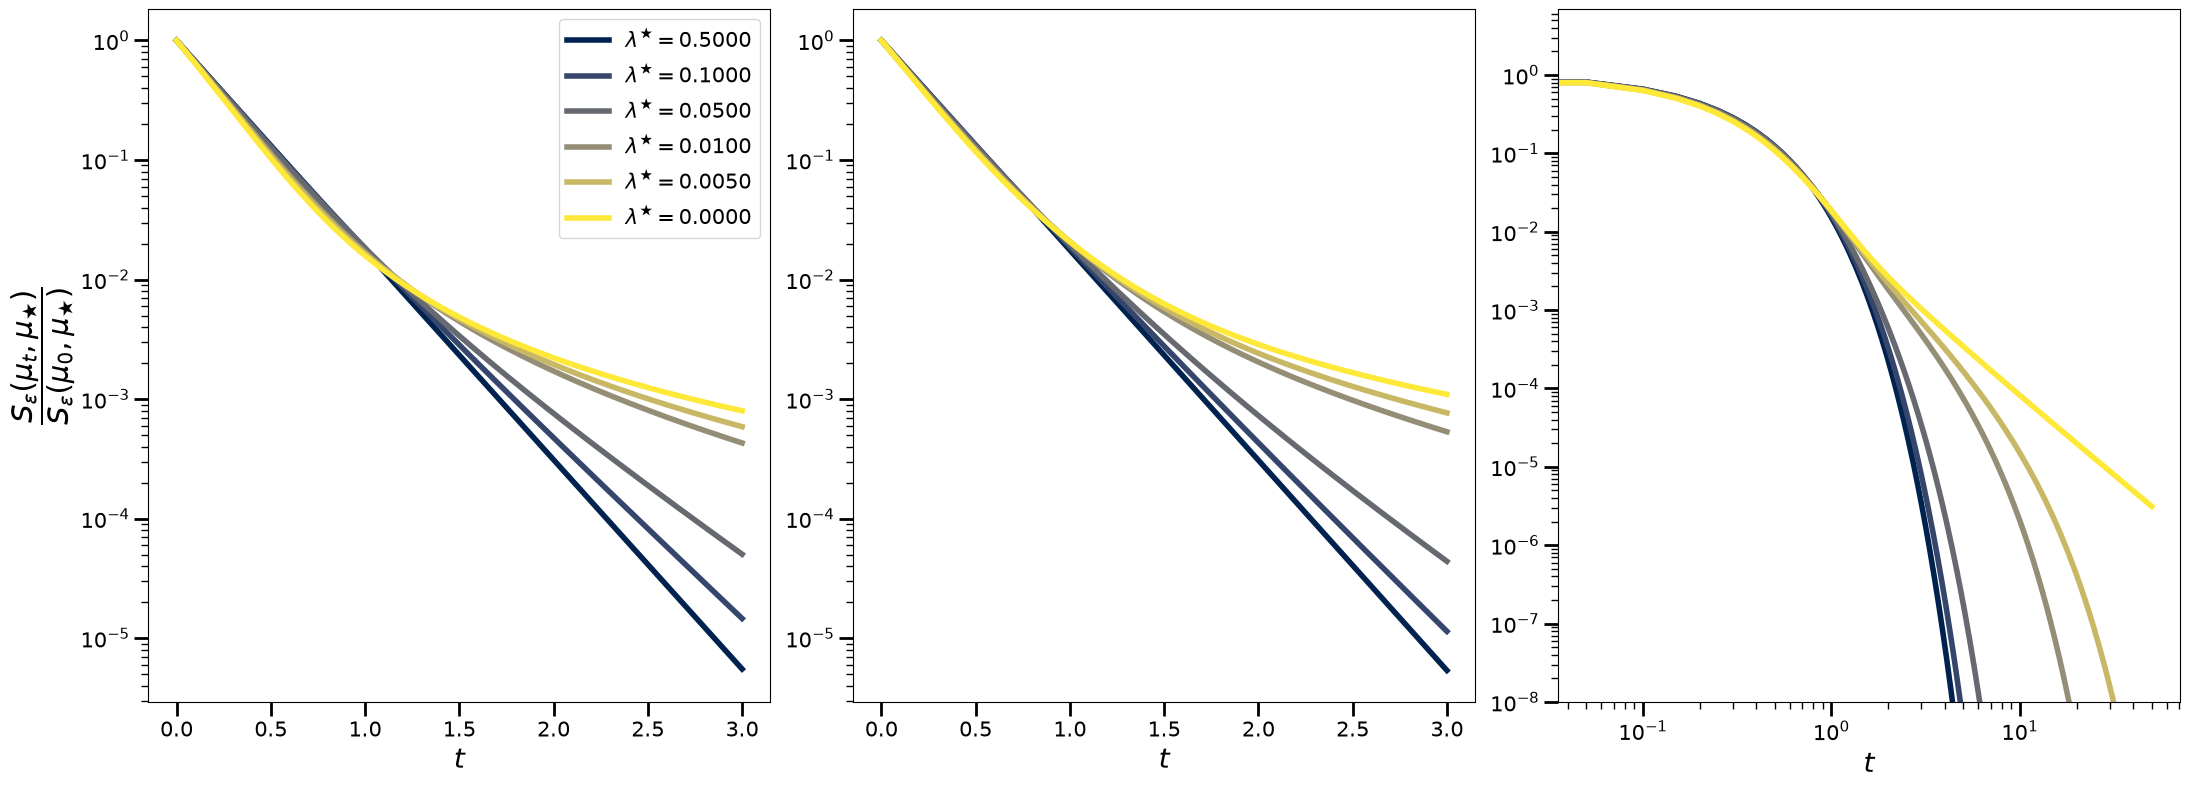

In [6]:
# Figure 3
fig = plt.figure(figsize=(22, 8))
ax1 = fig.add_subplot(1, 3, 1)
ax2 = fig.add_subplot(1, 3, 2, sharey=ax1)
ax3 = fig.add_subplot(1, 3, 3)
lam_list = [5e-1, 1e-1, 5e-2, 1e-2, 5e-3, 0]
n = len(lam_list)
sigma_0_list = [torch.tensor([[1., 0],
                              [0., 1.]])]*n

sigma_star_list = [torch.tensor([[1., 0.],
                                 [0., l]]) for l in lam_list]
blur_list = [.5]*n
t = torch.linspace(0, 3, 200)
ax1 = plot_cv_speed(ax1, sigma_0_list, sigma_star_list, blur_list, t, labels=[r"$\lambda^{\bigstar} = "+ f'{l:.4f}$' for l in lam_list],)

sigma_0_list = [torch.tensor([[.6, .3],
                              [.3, .6]])]*n
ax2 = plot_cv_speed(ax2, sigma_0_list, sigma_star_list, blur_list, t, labels=[r"$\lambda^{\bigstar} = " + f'{l:.4f}$' for l in lam_list], showylabel=False, showlegend=False)
ax3 = plot_cv_speed(ax3, sigma_0_list, sigma_star_list, blur_list, torch.linspace(0, 50, 1000), labels=[r"$\lambda^{\bigstar} = " + f'{l:.4f}$' for l in lam_list], showylabel=False, showlegend=False)
ax3.set_ylim(bottom = 1e-8)
ax3.set_xscale('log')

fig.tight_layout()

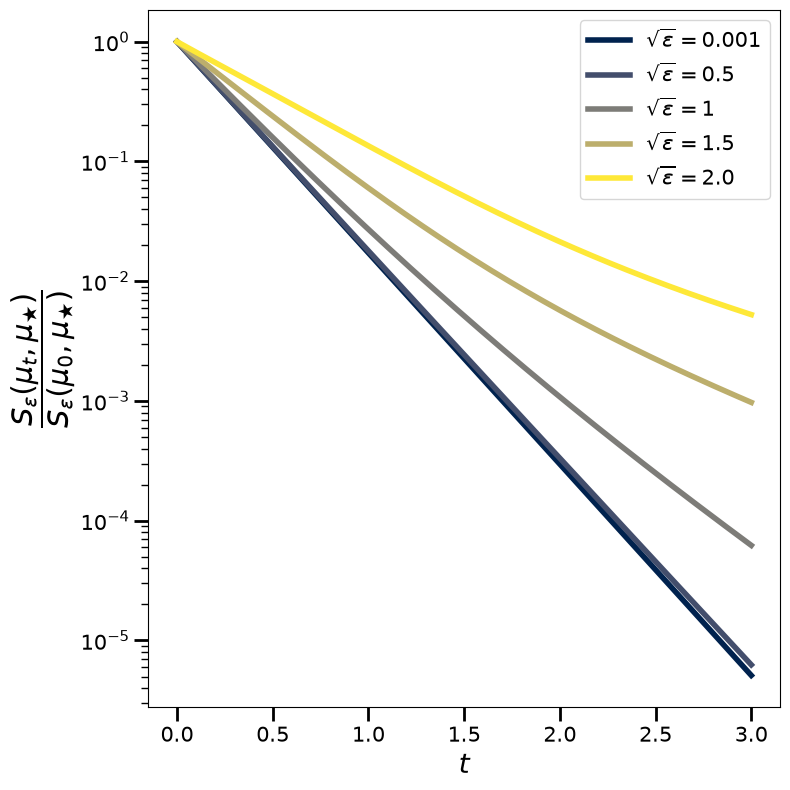

In [7]:
# Figure 4
blur_list = [.001, .5, 1, 1.5, 2.]
n = len(blur_list)
fig, ax1 = plt.subplots(figsize=(8, 8))
sigma_0_list = [torch.tensor([[.6, .3],
                          [.3, .6]])]*n
sigma_star_list = [torch.diag(torch.tensor([1., .2]))]*n
t = torch.linspace(0, 3, 200)
ax1 = plot_cv_speed(ax1, sigma_0_list, sigma_star_list, blur_list, t, labels=[r"$\sqrt{\varepsilon} = "+f"{blur}$" for blur in blur_list])
fig.tight_layout()

# Beyond Gaussian measures: the swiss roll

In [43]:
# Set seed for reproducibility. Note that running cells in a different order may then yield a different result

torch.manual_seed(0)

In [44]:
# Plot limits
xlim3d = (-20, 20)
ylim3d = (-10, 30)
zlim3d = (-20, 20)

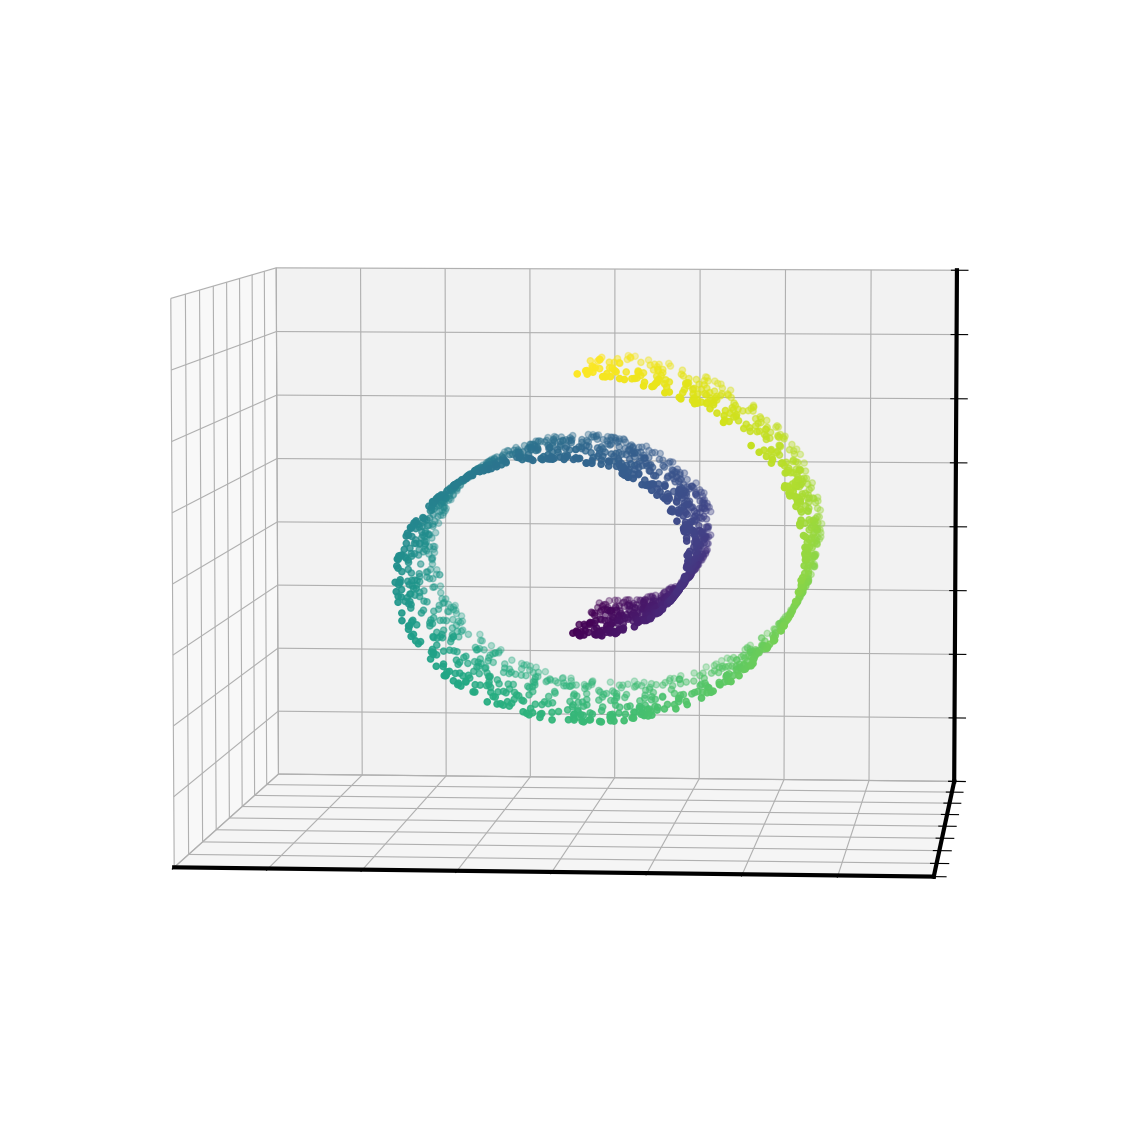

In [45]:
# Fig. 5
x = make_swiss_roll(2000)[0]
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')
ax.scatter3D(x[:, 0], x[:, 1], x[:, 2], c=np.sqrt((x[:, [0, 2]]**2).sum(1)))
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.line.set_linewidth(3)
    axis.set_ticklabels([])
ax.view_init(azim=-85, elev=5)
ax.set(xlim3d=xlim3d, ylim3d=ylim3d, zlim3d=zlim3d)
fig.subplots_adjust(top=1.2, bottom=-.2, left=-.1, right=1.1)
fig.savefig("./figures/swiss-roll.jpg", dpi=300)

In [46]:
# Parameters and target samplers

def blur_formula(target, n=10000):
    x = target(n)
    if x.shape[1] > 1:
        return torch.sqrt(.05*torch.trace(torch.cov(x.T))/x.shape[1]).item()
    return torch.sqrt(.05*torch.cov(x.T)).item()

t = torch.cat((torch.arange(0, 1, .1), torch.arange(1, 15.25, .25)))

N = 1000

# Raw
target_raw = lambda n: torch.tensor(make_swiss_roll(n)[0], device=device)
blur = blur_formula(target_raw)
Skdiv = SamplesLoss(blur=blur, backend="tensorized", cost=euclidean_cost_batch)

# Manifold
def target_manifold(n):
    x, s = make_swiss_roll(n)
    return torch.column_stack((torch.tensor(s), torch.tensor(x)[:, 1])).to(device)

blur_manifold = blur_formula(target_manifold)
Skdiv_manifold = SamplesLoss(blur=blur_manifold, backend="tensorized", cost=euclidean_cost_batch)

In [47]:
# Initialize models. When using the pre-trained models, the parameters should match that of the stored models (see README).
model = MLP_drifting(10, 250, 250, 3).to(device)
model_manifold = MLP_drifting(10, 250, 250, 2).to(device)

## Drifting model training (skip to use stored models)

### Drifting model in raw coordinates

In [48]:
model.train()

# Learn the initial distribution to be a Gaussian with same mean and variance as the target
s = torch.linspace(0, 20, 40)

mean = torch.tensor(make_swiss_roll(10000)[0].mean(0), device=device)
std = torch.sqrt(torch.cov(torch.tensor(make_swiss_roll(10000)[0], device=device).T).trace())

model.train_drifting(lambda n: mean + std*torch.randn(n, model.output_dim, device=device), s, sample_size=500, blur=1, max_sinkhorn_steps=100, sinkhorn_tol=1e-2, return_params_t=False)

[None]

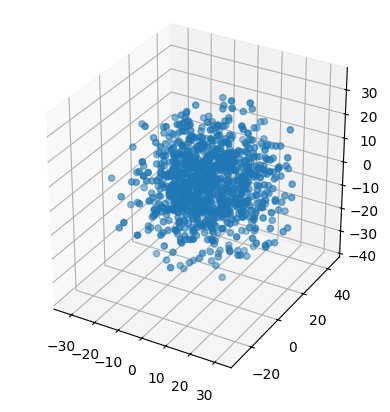

In [49]:
x = model.sample(1000).cpu().detach()
fig = plt.figure()
ax = fig.add_subplot(projection='3d')
ax.scatter3D(x[:,0], x[:,1], x[:, 2])
ax.set(aspect='equal')

In [50]:
# Approximate the flow

model_params_t = model.train_drifting(target_raw, t, sample_size=N, blur=blur, max_sinkhorn_steps=100, sinkhorn_tol=5e-2)

In [ ]:
# Use to save model
dirname = f"models_{model.input_dim}_{model.hidden_dim_1}_{model.hidden_dim_2}_{model.output_dim}"
os.mkdir(dirname)
for i, params in enumerate(model_params_t):
    torch.save(params, dirname+rf'/model_{i}.pt')

### Drifting model in manifold coordinates

In [52]:
model_manifold.train()

# Learn the initial distribution to be a Gaussian with same mean and variance as the target
mean_manifold = target_manifold(10000).mean(0)
std_manifold = torch.sqrt(torch.cov(target_manifold(10000).T).trace())

s = torch.linspace(0, 20, 40)

model_manifold.train_drifting(lambda n: mean_manifold + std_manifold*torch.randn(n, model_manifold.output_dim, device=device),
                         s, sample_size=100, blur=1, max_sinkhorn_steps=100, sinkhorn_tol=1e-2, return_params_t=False)

[None]

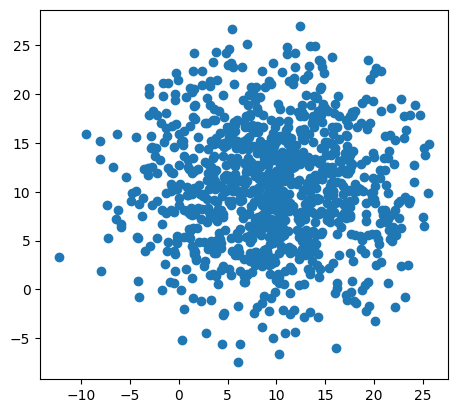

In [53]:
x_manifold = model_manifold.sample(1000).cpu().detach()
fig, ax = plt.subplots()
ax.scatter(x_manifold[:,0], x_manifold[:, 1])
ax.set(aspect="equal")

In [54]:
# Approximate the flow

model_manifold_params_t = model_manifold.train_drifting(target_manifold, t, sample_size=N, blur=blur_manifold, max_sinkhorn_steps=100, sinkhorn_tol=5e-2)

In [ ]:
# Use to save model
dirname = f"models_{model_manifold.input_dim}_{model_manifold.hidden_dim_1}_{model_manifold.hidden_dim_2}_{model_manifold.output_dim}"
os.mkdir(dirname)
for i, params in enumerate(model_manifold_params_t):
    torch.save(params, dirname+rf'/model_{i}.pt')

## Load stored models (skip if training was done)

In [ ]:
model_params_t = [torch.load(f"./models_{model.input_dim}_{model.hidden_dim_1}_{model.hidden_dim_2}_{model.output_dim}/model_{i}.pt",map_location=device) for i in range(len(t))]

model_manifold_params_t = [torch.load(f"./models_{model_manifold.input_dim}_{model_manifold.hidden_dim_1}_{model_manifold.hidden_dim_2}_{model_manifold.output_dim}/model_{i}.pt", map_location=device) for i in range(len(t))]

## Results

In [56]:
# Compute losses for the raw model
losses = []
stdivs = []
model.eval()
for params in model_params_t:
    model.load_state_dict(params)
    l = []
    for _ in range(10):
        with torch.no_grad():
            x = model.sample(N)
            l.append(Skdiv(x, target_raw(N)).item())
    losses.append(np.mean(l))
    stdivs.append(np.std(l))
losses = np.array(losses)
stdivs = np.array(stdivs)

In [57]:
# Compute losses for the manifold model
losses_manifold = []
stdivs_manifold = []
model_manifold.eval()
for params in model_manifold_params_t:
    model_manifold.load_state_dict(params)
    l = []
    for _ in range(10):
        with torch.no_grad():
            x = model_manifold.sample(N)
            l.append(Skdiv_manifold(x, target_manifold(N)).item())
    losses_manifold.append(np.mean(l))
    stdivs_manifold.append(np.std(l))
losses_manifold = np.array(losses_manifold)
stdivs_manifold = np.array(stdivs_manifold)

In [58]:
# Lower bound in raw space
l = []
for _ in range(500):
    l.append(Skdiv(target_raw(N), target_raw(N)).item())
lower_bound = np.mean(l)
lower_bound_stdiv = np.std(l)

In [59]:
# Lower bound in manifold
l = []
for i in range(500):
    l.append(Skdiv_manifold(target_manifold(N), target_manifold(N)).item())
lower_bound_manifold = np.mean(l)
lower_bound_stdiv_manifold = np.std(l)

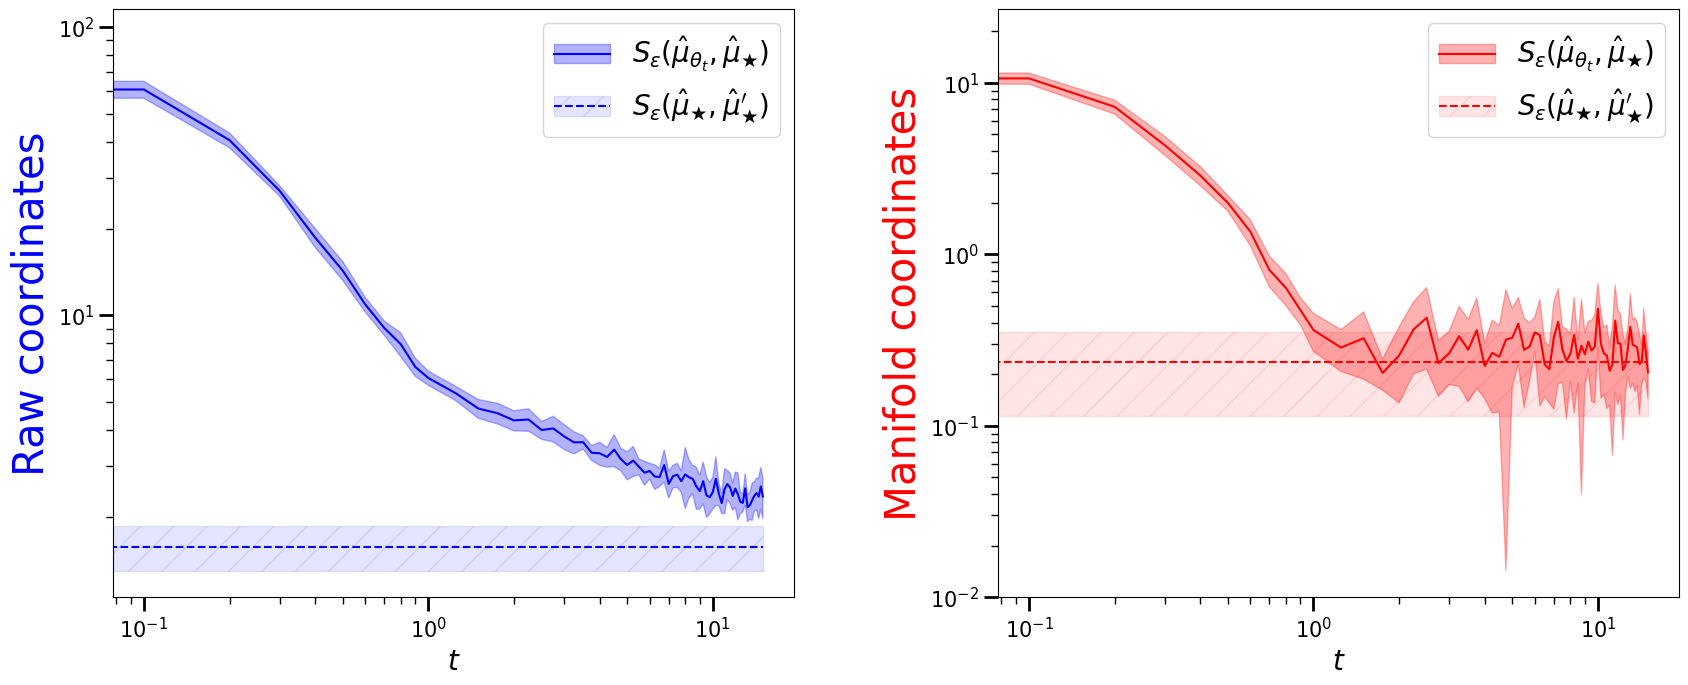

In [60]:
# Fig. 6
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ax0, ax1 = axes

avg_blue, = ax0.plot(t, losses, label=r'$S_\varepsilon(\hat\mu_{\theta_t}, \hat\mu_\bigstar)$', c='blue')
std_blue = ax0.fill_between(t, (losses-stdivs), (losses+stdivs), alpha=.3, color='blue')
avg_blue_dashed, = ax0.plot(t, lower_bound*np.ones_like(t), c='blue', label=r"$S_\varepsilon(\hat\mu_\bigstar, \hat\mu_\bigstar')$", linestyle='--')
std_blue_hatched = ax0.fill_between(t, (lower_bound-lower_bound_stdiv)*np.ones_like(t), (lower_bound+lower_bound_stdiv)*np.ones_like(t), alpha=.1, color='blue', hatch='/')

avg_red, = ax1.plot(t, losses_manifold, label=r'$S_\varepsilon(\hat\mu_{\theta_t}, \hat\mu_\bigstar)$', c='red')
std_red = ax1.fill_between(t, (losses_manifold-stdivs_manifold), (losses_manifold+stdivs_manifold), alpha=.3, color='red')
avg_red_dashed, = ax1.plot(t, lower_bound_manifold*np.ones_like(t), c='red', label=r"$S_\varepsilon(\hat\mu_\bigstar, \hat\mu_\bigstar')$", linestyle='--')
std_red_hatched = ax1.fill_between(t, (lower_bound_manifold-lower_bound_stdiv_manifold)*np.ones_like(t),
                (lower_bound_manifold+lower_bound_stdiv_manifold)*np.ones_like(t), alpha=.1, color='red', hatch='/')

ax0.set_ylabel(r'Raw coordinates', fontdict=dict(size=30, color='blue'))
ax0.set_xlabel('$t$', fontdict=dict(size=20))
ax1.set_ylabel(r'Manifold coordinates', fontdict=dict(size=30, color='red'))
ax1.set_xlabel('$t$', fontdict=dict(size=20))

for ax, elements in zip(axes, [[(avg_blue, std_blue), (avg_blue_dashed, std_blue_hatched)], [(avg_red, std_red), (avg_red_dashed, std_red_hatched)]]):
    ax.set(yscale='log',xscale='log')
    ax.tick_params(axis='both', which="major", labelsize=15, length=10, width=2)
    ax.tick_params(axis='both', which="minor", length=5, width=1)
    labels = [elements[i][0].get_label() for i in range(2)]
    ax.legend(elements, labels, handler_map={tuple: HandlerTuple()}, fontsize=20)
fig.subplots_adjust(wspace=.3, top=.95, left=0.08, right=.95)
fig.savefig(f"./figures/losses_{model.input_dim}_{model.hidden_dim_1}_{model.hidden_dim_2}_{model.output_dim}__{model_manifold.input_dim}_{model_manifold.hidden_dim_1}_{model_manifold.hidden_dim_2}_{model_manifold.output_dim}.jpg", dpi=300)  

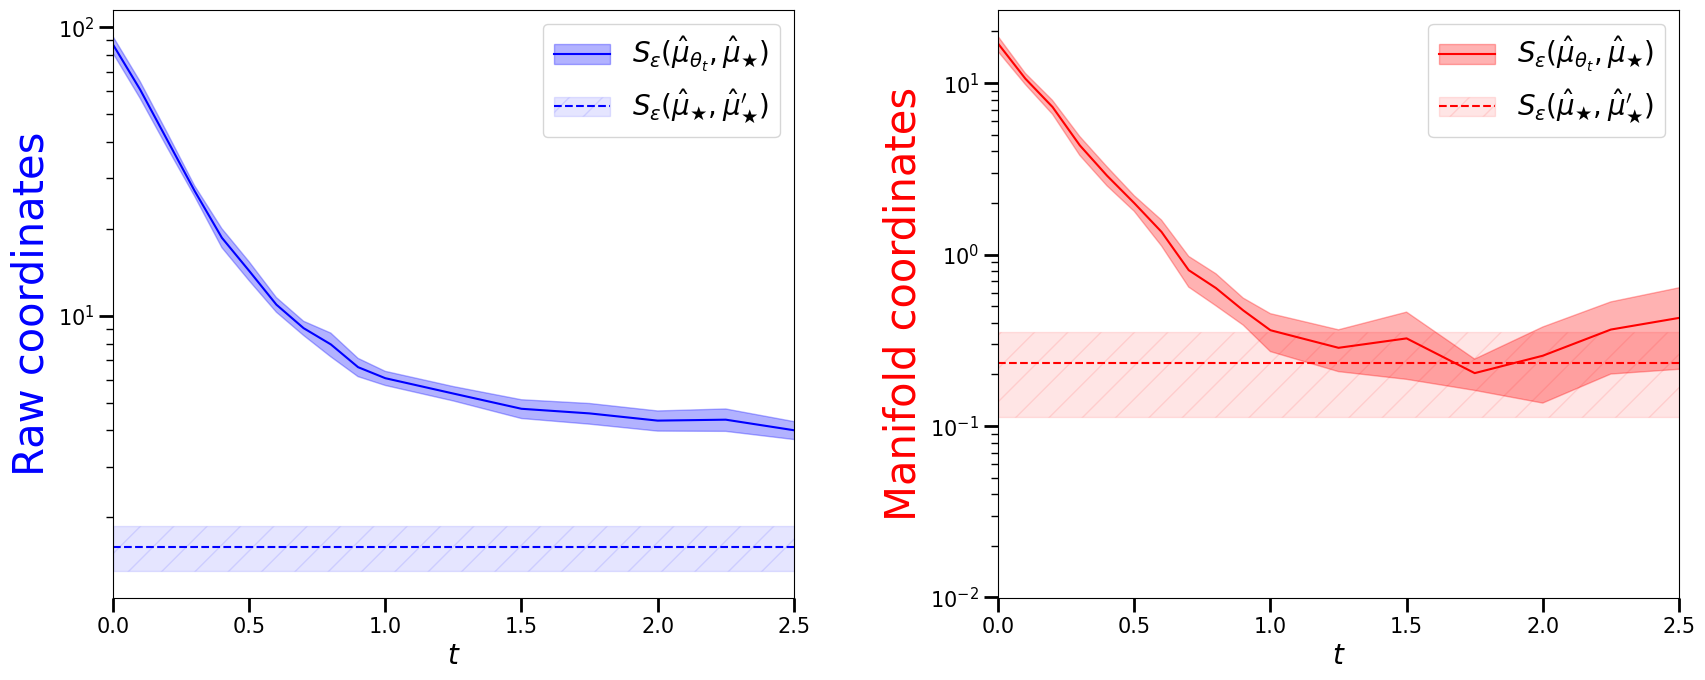

In [61]:
# Same figure but in semilog
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
ax0, ax1 = axes

avg_blue, = ax0.plot(t, losses, label=r'$S_\varepsilon(\hat\mu_{\theta_t}, \hat\mu_\bigstar)$', c='blue')
std_blue = ax0.fill_between(t, (losses-stdivs), (losses+stdivs), alpha=.3, color='blue')
avg_blue_dashed, = ax0.plot(t, lower_bound*np.ones_like(t), c='blue', label=r"$S_\varepsilon(\hat\mu_\bigstar, \hat\mu_\bigstar')$", linestyle='--')
std_blue_hatched = ax0.fill_between(t, (lower_bound-lower_bound_stdiv)*np.ones_like(t), (lower_bound+lower_bound_stdiv)*np.ones_like(t), alpha=.1, color='blue', hatch='/')

avg_red, = ax1.plot(t, losses_manifold, label=r'$S_\varepsilon(\hat\mu_{\theta_t}, \hat\mu_\bigstar)$', c='red')
std_red = ax1.fill_between(t, (losses_manifold-stdivs_manifold), (losses_manifold+stdivs_manifold), alpha=.3, color='red')
avg_red_dashed, = ax1.plot(t, lower_bound_manifold*np.ones_like(t), c='red', label=r"$S_\varepsilon(\hat\mu_\bigstar, \hat\mu_\bigstar')$", linestyle='--')
std_red_hatched = ax1.fill_between(t, (lower_bound_manifold-lower_bound_stdiv_manifold)*np.ones_like(t),
                (lower_bound_manifold+lower_bound_stdiv_manifold)*np.ones_like(t), alpha=.1, color='red', hatch='/')

ax0.set_ylabel(r'Raw coordinates', fontdict=dict(size=30, color='blue'))
ax0.set_xlabel('$t$', fontdict=dict(size=20))
ax1.set_ylabel(r'Manifold coordinates', fontdict=dict(size=30, color='red'))
ax1.set_xlabel('$t$', fontdict=dict(size=20))

for ax, elements in zip(axes, [[(avg_blue, std_blue), (avg_blue_dashed, std_blue_hatched)], [(avg_red, std_red), (avg_red_dashed, std_red_hatched)]]):
    ax.set(yscale='log', xlim=(0, 2.5))
    ax.tick_params(axis='both', which="major", labelsize=15, length=10, width=2)
    ax.tick_params(axis='both', which="minor", length=5, width=1)
    labels = [elements[i][0].get_label() for i in range(2)]
    ax.legend(elements, labels, handler_map={tuple: HandlerTuple()}, fontsize=20)
fig.subplots_adjust(wspace=.3, top=.95, left=0.08, right=.95)
fig.savefig(f"./figures/losses_semilog_{model.input_dim}_{model.hidden_dim_1}_{model.hidden_dim_2}_{model.output_dim}__{model_manifold.input_dim}_{model_manifold.hidden_dim_1}_{model_manifold.hidden_dim_2}_{model_manifold.output_dim}.jpg", dpi=300)

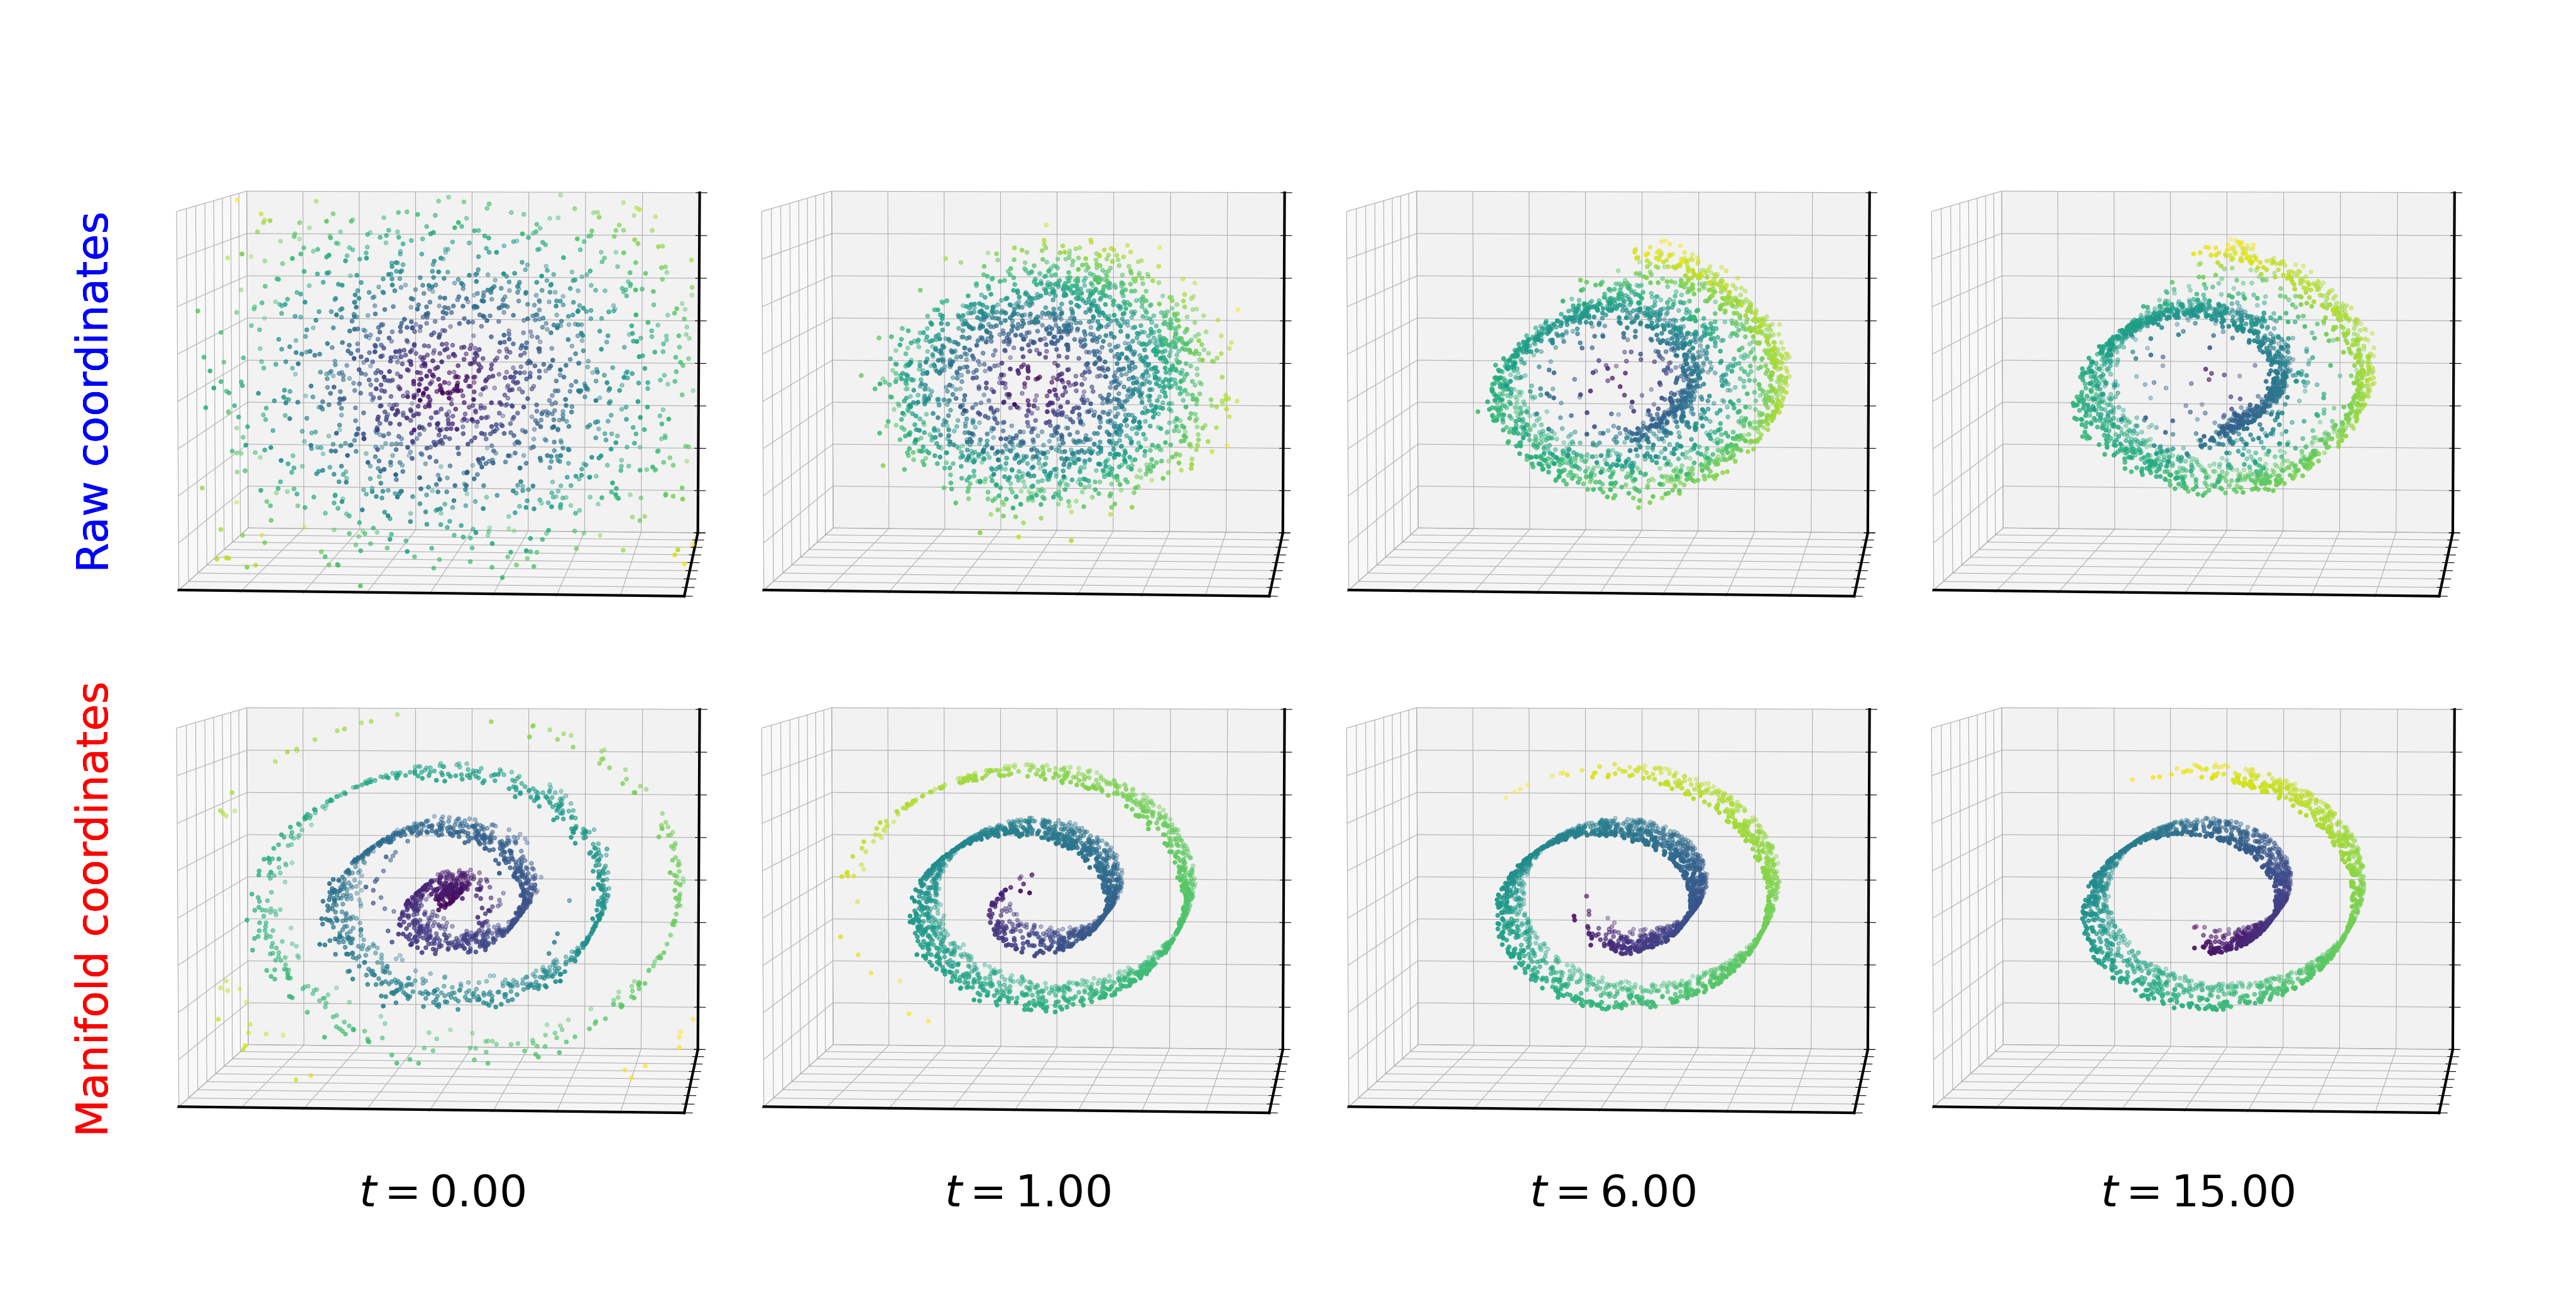

In [62]:
# Fig. 7
fig = plt.figure(figsize=(40, 18))
gs = fig.add_gridspec(3, 5, height_ratios=[1, 1, .2], width_ratios=[.3, 1, 1, 1, 1])

for i, j in enumerate([0, 10, 30, 66]):
    ax = fig.add_subplot(gs[0, i+1], projection='3d')
    ax.patch.set_alpha(0)
    model.load_state_dict(model_params_t[j])
    model.eval()
    x = model(torch.randn(2000, model.input_dim, device=device)).cpu().detach().numpy()
    conditions = (x[:, 0]>=xlim3d[0]) & (x[:, 0]<=xlim3d[1]) & (x[:, 1]>=ylim3d[0]) & (x[:, 1]<=ylim3d[1]) & (x[:, 2]>=zlim3d[0]) & (x[:, 2]<=zlim3d[1]) 
    x[np.logical_not(conditions),:] = np.nan
    ax.scatter3D(x[:, 0], x[:, 1], x[:, 2], c=np.sqrt((x[:, [0, 2]]**2).sum(1)))
    ax.set(xlim3d=xlim3d, ylim3d=ylim3d, zlim3d=zlim3d)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.line.set_linewidth(3)
        axis.set_ticklabels([])
    ax.view_init(azim=-85, elev=5)

    ax = fig.add_subplot(gs[1, i+1], projection='3d')
    ax.patch.set_alpha(0)
    model_manifold.load_state_dict(model_manifold_params_t[j])
    model_manifold.eval()
    x_ = model_manifold(torch.randn(2000, model_manifold.input_dim, device=device)).cpu().detach()
    x = torch.column_stack(( x_[:, 0] * torch.cos(x_[:, 0]) , x_[:, 1], x_[:, 0] * torch.sin(x_[:, 0]))).cpu().numpy()
    conditions = (x[:, 0]>=xlim3d[0]) & (x[:, 0]<=xlim3d[1]) & (x[:, 1]>=ylim3d[0]) & (x[:, 1]<=ylim3d[1]) & (x[:, 2]>=zlim3d[0]) & (x[:, 2]<=zlim3d[1]) 
    x[np.logical_not(conditions),:] = np.nan
    ax.scatter3D(x[:, 0], x[:, 1], x[:, 2], c=np.sqrt((x[:, [0, 2]]**2).sum(1)))
    ax.set(xlim3d=xlim3d, ylim3d=ylim3d, zlim3d=zlim3d)
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.line.set_linewidth(3)
        axis.set_ticklabels([])
    ax.view_init(azim=-85, elev=5)

    ax = fig.add_subplot(gs[2, i+1])
    ax.set_axis_off()
    ax.text(.5, 0, f"$t = {t[j]:.2f}$", fontdict=dict(size=50), horizontalalignment='center', verticalalignment='center')

    ax = fig.add_subplot(gs[0, 0])
    ax.set_axis_off()
    ax.text(0.4, .5, "Raw coordinates", fontdict=dict(size=50, color="blue"), rotation=90, horizontalalignment='center', verticalalignment='center')

    ax = fig.add_subplot(gs[1, 0])
    ax.set_axis_off()
    ax.text(0.4, .5, "Manifold coordinates", fontdict=dict(size=50, color="red"), rotation=90, horizontalalignment='center', verticalalignment='center')

fig.patch.set_alpha(0)
fig.subplots_adjust(wspace=-.25, hspace=-.45, left=0, top=1.1, right=1.02, bottom=.05)
fig.savefig(f'./figures/flows_{model.input_dim}_{model.hidden_dim_1}_{model.hidden_dim_2}_{model.output_dim}__{model_manifold.input_dim}_{model_manifold.hidden_dim_1}_{model_manifold.hidden_dim_2}_{model_manifold.output_dim}.jpg', dpi=300)